In [93]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np

# DATA CLEANING

# Loading data
processed = "/Users/eshagupta/Downloads/CMU/Fall'26/Python/Final Project/boston-mbta-ridership/data/processed"

ridership = pd.read_csv("/Users/eshagupta/Downloads/CMU/Fall'26/Python/Final Project/boston-mbta-ridership/data/processed/ridership_route_year.csv", dtype={'route_id': str})
demographic = pd.read_csv("/Users/eshagupta/Downloads/CMU/Fall'26/Python/Final Project/boston-mbta-ridership/data/processed/route_area_demographics.csv", dtype={'tract': str})
routes = ["22", "23", "28", "29"]

print("\033[1m" + "Ridership data" + "\033[0m")
display(ridership.head())
print("\033[1m" + "Median Income" + "\033[0m")
display(demographic.head())

# Filering to relevant routes
ridership_by_routes = ridership[ridership["route_id"].isin(routes) & (ridership["day_type"] == "weekday")].copy()
print("\033[1m" + "Ridership for relevant routes" + "\033[0m")
display(ridership_by_routes.head())

# Filtering to relevant routes and columns in demographic (median income) dataset
median_income_by_routes = demographic[demographic["route_id"].isin(routes)][["route_id", "acs_period", "residents", "median_income_est", "fare_free"]]

# Creating acs_period column in ridership dataset
ridership_by_routes["acs_period"] = ridership_by_routes["year"].apply(lambda y: "2015-2019" if y <=2019 else "2020-2024") 

# Merging datasets
ridership_median_income = ridership_by_routes.merge(median_income_by_routes, on=["route_id", "acs_period"], how="left").drop(columns=["fare_free_x"]).rename(columns={"fare_free_y":"fare_free"})
ridership_median_income = ridership_median_income[["route_id", "fare_free", "year", "acs_period", "day_type", "avg_daily_boardings",	"residents", "median_income_est"]]

print("\033[1m" + "Ridership and median incomes for relevant routes" + "\033[0m")
display(ridership_median_income.head())

Ridership data


,route_id,year,day_type,fare_free,avg_daily_boardings
0,1,2016,saturday,False,8526.0
1,1,2016,sunday,False,5732.3
2,1,2016,weekday,False,11416.3
3,1,2017,saturday,False,9585.5
4,1,2017,sunday,False,6646.3


Median Income


,route_id,acs_period,residents,median_income_est,pct_poverty,pct_no_vehicle,pct_minority,pct_transit,pct_long_commute,pct_renters,pct_rent_burdened,unemployment_rate,pct_area_in_boston,fare_free
0,1,2015-2019,39927.0,54613.0,27.2,52.5,52.2,30.5,15.7,77.3,50.7,8.9,51.4,False
1,10,2015-2019,82788.0,82453.0,19.6,36.6,49.6,33.4,17.3,63.3,43.7,6.0,87.1,False
2,101,2015-2019,787.0,142563.0,2.9,6.8,13.3,27.3,15.3,41.6,39.5,1.3,3.9,False
3,104,2015-2019,4697.0,65652.0,12.5,44.5,74.5,62.6,26.8,75.6,51.5,3.0,4.3,False
4,105,2015-2019,1518.0,142563.0,2.9,6.8,13.3,27.3,15.3,41.6,39.5,1.3,11.4,False


Ridership for relevant routes


,route_id,year,day_type,fare_free,avg_daily_boardings
1044,22,2016,weekday,False,8165.7
1047,22,2017,weekday,False,8014.8
1050,22,2018,weekday,False,7982.1
1053,22,2019,weekday,False,8411.7
1056,22,2020,weekday,False,4155.0


Ridership and median incomes for relevant routes


,route_id,fare_free,year,acs_period,day_type,avg_daily_boardings,residents,median_income_est
0,22,False,2016,2015-2019,weekday,8165.7,72297.0,38561.0
1,22,False,2017,2015-2019,weekday,8014.8,72297.0,38561.0
2,22,False,2018,2015-2019,weekday,7982.1,72297.0,38561.0
3,22,False,2019,2015-2019,weekday,8411.7,72297.0,38561.0
4,22,False,2020,2020-2024,weekday,4155.0,72759.0,56874.0


# G1

Route Profile across Characteristics


,route_id,acs_period,fare_free,residents,median_income_est,pct_poverty,pct_no_vehicle,pct_minority,pct_rent_burdened
26,22,2015-2019,False,72297.0,38561.0,31.4,44.2,77.8,55.0
27,23,2015-2019,True,55899.0,39936.0,28.2,41.4,84.7,57.0
32,28,2015-2019,True,69296.0,35322.0,31.2,44.0,82.6,56.6
33,29,2015-2019,True,46596.0,38715.0,28.9,39.5,92.9,56.6
252,22,2020-2024,False,72759.0,56874.0,27.1,41.9,77.8,52.8
253,23,2020-2024,True,58015.0,54927.0,23.5,36.9,84.7,54.9
258,28,2020-2024,True,68680.0,50708.0,27.2,41.4,82.1,56.5
259,29,2020-2024,True,44247.0,55527.0,26.3,37.3,91.1,54.7


Text(0, 0.5, '% Rent Burdened')

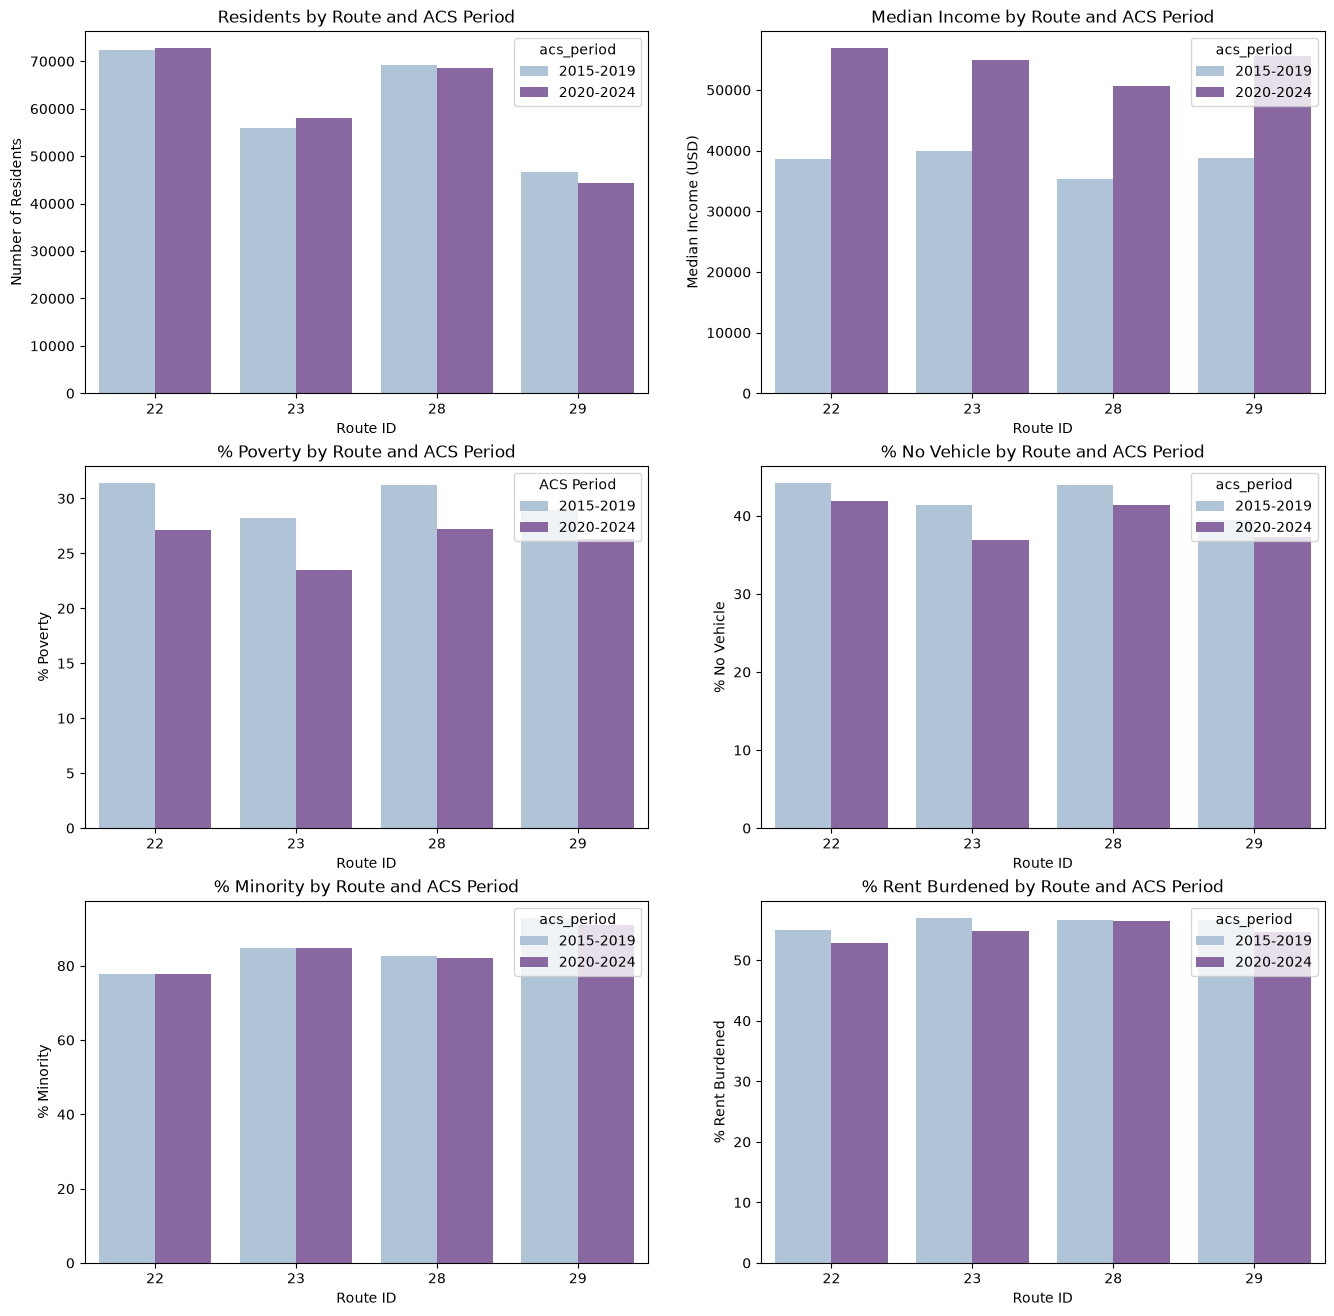

In [161]:
import matplotlib.pyplot as plt
import seaborn as sns

# Four-route profile: residents, income, poverty, no car, minority, rent burden
route_profile = demographic[demographic["route_id"].isin(routes)][["route_id", "acs_period", "fare_free", "residents", "median_income_est", "pct_poverty", "pct_no_vehicle", "pct_minority", "pct_rent_burdened"]]
print("\033[1m" + "Route Profile across Characteristics" + "\033[0m")
display(route_profile)

# Visualization
fig, axes = plt.subplots(nrows = 3, ncols= 2, figsize = (16, 16))

# residents
sns.barplot(data=route_profile, x="route_id", y="residents", hue="acs_period", palette="BuPu", ax=axes[0,0])
axes[0,0].set_title("Residents by Route and ACS Period")
axes[0,0].set_ylabel("Number of Residents")
axes[0,0].set_xlabel("Route ID")    

# median income
sns.barplot(data=route_profile, x="route_id", y="median_income_est", hue="acs_period", palette="BuPu", ax=axes[0,1])
axes[0,1].set_title("Median Income by Route and ACS Period")
axes[0,1].set_xlabel("Route ID")
axes[0,1].set_ylabel("Median Income (USD)")

# % poverty
sns.barplot(data=route_profile, x="route_id", y="pct_poverty", hue="acs_period", palette="BuPu", ax=axes[1,0])
axes[1,0].set_title("% Poverty by Route and ACS Period")
axes[1,0].set_xlabel("Route ID")
axes[1,0].set_ylabel("% Poverty")
axes[1,0].legend(loc="upper right", title="ACS Period")

# % no income
sns.barplot(data=route_profile, x="route_id", y="pct_no_vehicle", hue="acs_period", palette="BuPu", ax=axes[1,1])
axes[1,1].set_title("% No Vehicle by Route and ACS Period")
axes[1,1].set_xlabel("Route ID")
axes[1,1].set_ylabel("% No Vehicle")

# % minority
sns.barplot(data=route_profile, x="route_id", y="pct_minority", hue="acs_period", palette="BuPu", ax=axes[2,0])
axes[2,0].set_title("% Minority by Route and ACS Period")
axes[2,0].set_xlabel("Route ID")
axes[2,0].set_ylabel("% Minority")

# % rent burdened
sns.barplot(data=route_profile, x="route_id", y="pct_rent_burdened", hue="acs_period", palette="BuPu", ax=axes[2,1])
axes[2,1].set_title("% Rent Burdened by Route and ACS Period")
axes[2,1].set_xlabel("Route ID")
axes[2,1].set_ylabel("% Rent Burdened") 

# F1

In [142]:
# Grouped bars	Low-income, minority, no car, commuting to work: 23, 28 & 29, 22, All Bus (2025)
routes2 = ["22", "23", "28", "28 & 29", "Roxbury/Dorchester/Mattapan/South End - West", "Roxbury/Dorchester/Mattapan/South End - East", "Roxbury/Dorchester/Mattapan/South End & Jamaica Plain/Roslindale/Hyde Park"]
survey = pd.read_csv("/Users/eshagupta/Downloads/CMU/Fall'26/Python/Final Project/boston-mbta-ridership/data/processed/surveys_clean.csv", dtype={'route_id': str})
survey.columns
survey_filtered = survey[(survey["survey_year"] == "2025") & 
       (survey["route_group"].isin(routes2)) &
       (
           ((survey["measure"] == "low_income") & (survey["category"] == "yes")) |
       ((survey["measure"] == "minority") & (survey["category"] == "yes")) |
       ((survey["measure"] == "vehicles") & (survey["category"] == "0")) |
       ((survey["measure"] == "trip_purpose") & (survey["category"] == "work"))
       )].copy()
survey_filtered

# making indicator names more readable
survey_filtered["indicator"] = survey_filtered["measure"]

survey_filtered.loc[survey_filtered["measure"] == "low_income", "indicator"] = "Low income"
survey_filtered.loc[survey_filtered["measure"] == "minority", "indicator"] = "Minority"
survey_filtered.loc[survey_filtered["measure"] == "vehicles", "indicator"] = "No car"
survey_filtered.loc[survey_filtered["measure"] == "trip_purpose", "indicator"] = "Commuting to work"

# pivot table
survey_pivot = survey_filtered.pivot(
    index="route_group",
    columns="indicator",
    values="pct"
)

route_labels = {
    "Roxbury/Dorchester/Mattapan/South End - West": "Rox/Dor/Mat/SE West",
    "Roxbury/Dorchester/Mattapan/South End - East": "Rox/Dor/Mat/SE East",
    "Roxbury/Dorchester/Mattapan/South End & Jamaica Plain/Roslindale/Hyde Park": "Rox/Dor/Mat/SE + JPRH"
}

survey_pivot = survey_pivot.rename(index=route_labels)

survey_pivot


indicator,Commuting to work,Low income,Minority,No car
route_group,,,,
22,43.4,79.7,88.3,56.1
23,39.0,83.9,86.9,57.6
28 & 29,41.3,74.6,88.4,57.8
Rox/Dor/Mat/SE + JPRH,48.6,82.1,87.2,52.8
Rox/Dor/Mat/SE East,40.9,79.4,77.3,48.1
Rox/Dor/Mat/SE West,45.4,84.7,82.0,51.6


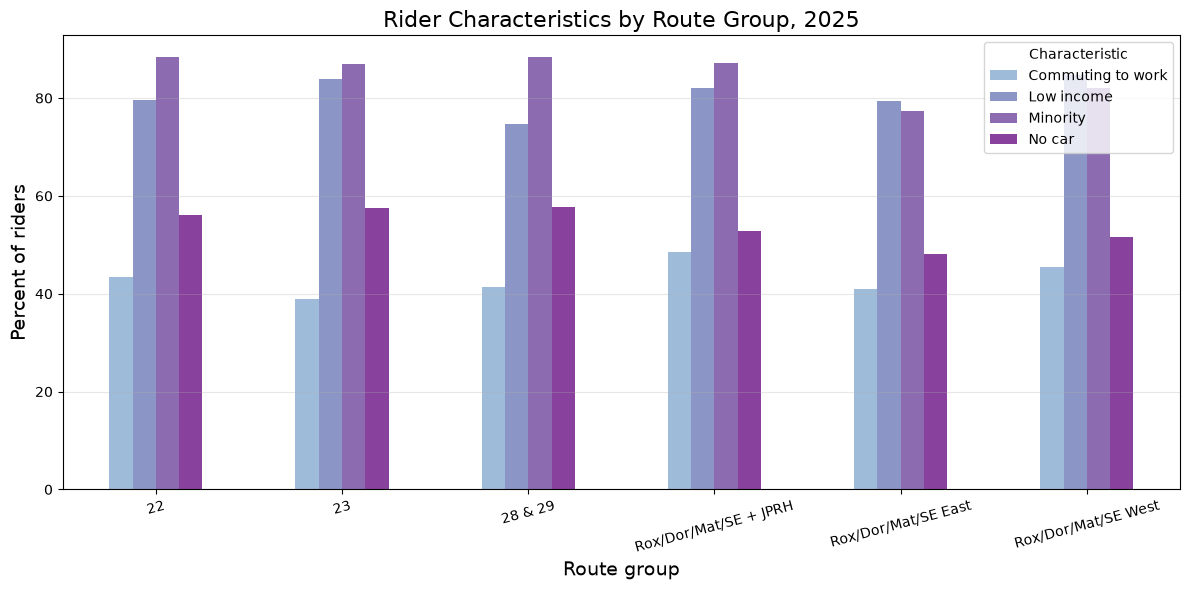

In [159]:
# Visualization
BuPu_colours = ["#9EBCDAFF", "#8C96C6FF", "#8C6BB1FF", "#88419DFF"]
    
ax = survey_pivot.plot(
    kind="bar",
    figsize=(12, 6),
    color=BuPu_colours,
)

ax.set_title("Rider Characteristics by Route Group, 2025", fontsize=16)
ax.set_xlabel("Route group", fontsize=14)
ax.set_ylabel("Percent of riders", fontsize=14)
ax.tick_params(axis="x", rotation=15)
ax.legend(title="Characteristic")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

G3: % of vehicle ownership change between 2015-2019 and 2020-2024

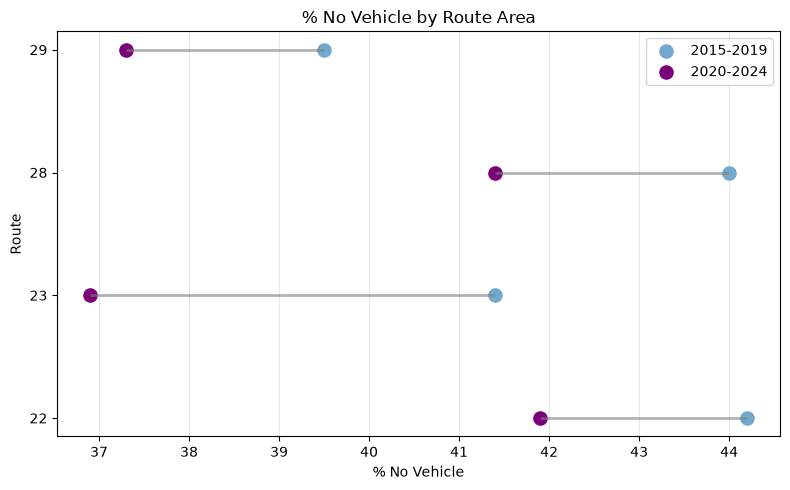

In [153]:
# Dumbbell chart: each route's neighborhood, 2015-2019 vs. 2020-2024

measure = "pct_no_vehicle"
measure_label = "% No Vehicle"

dumbbell = route_profile[
    ["route_id", "acs_period", measure]
].copy()

dumbbell_wide = dumbbell.pivot(
    index="route_id",
    columns="acs_period",
    values=measure
)

dumbbell_wide = dumbbell_wide.loc[routes]

# Visualization
fig, ax = plt.subplots(figsize=(8, 5))

y_positions = np.arange(len(dumbbell_wide))

ax.hlines(
    y=y_positions,
    xmin=dumbbell_wide["2015-2019"],
    xmax=dumbbell_wide["2020-2024"],
    color="gray",
    alpha=0.6,
    linewidth=2
)

ax.scatter(
    dumbbell_wide["2015-2019"],
    y_positions,
    color="#74a9cf",
    s=90,
    label="2015-2019"
)

ax.scatter(
    dumbbell_wide["2020-2024"],
    y_positions,
    color="#7a0177",
    s=90,
    label="2020-2024"
)

ax.set_yticks(y_positions)
ax.set_yticklabels(dumbbell_wide.index)

ax.set_title(f"{measure_label} by Route Area")
ax.set_xlabel(measure_label)
ax.set_ylabel("Route")

ax.legend()
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


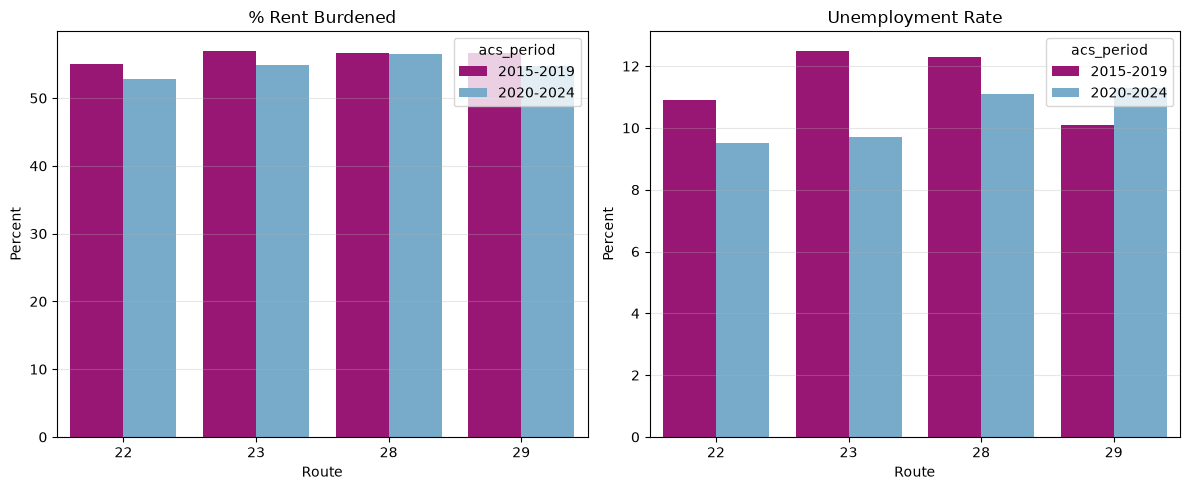

In [163]:
# Rent burden + unemployment	Side-by-side pair	pct_rent_burdened, unemployment_rate

route_profile_by_period = demographic[demographic["route_id"].isin(routes)][["route_id", "acs_period", "pct_rent_burdened", "unemployment_rate"]].copy()

colours = ["#ae017e", "#6baed6"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

sns.barplot(
    data=route_profile_by_period,
    x="route_id",
    y="pct_rent_burdened",
    hue="acs_period",
    palette=colours[:2],
    ax=axes[0]
)

axes[0].set_title("% Rent Burdened")
axes[0].set_xlabel("Route")
axes[0].set_ylabel("Percent")
axes[0].grid(axis="y", alpha=0.3)

sns.barplot(
    data=route_profile_by_period,
    x="route_id",
    y="unemployment_rate",
    hue="acs_period",
    palette=colours[:2],
    ax=axes[1]
)

axes[1].set_title("Unemployment Rate")
axes[1].set_xlabel("Route")
axes[1].set_ylabel("Percent")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Gap chart	Route 23 minus All Bus, in both survey years

trip_routes = ["22", "23", "28", "28 & 29", "All Bus", "Roxbury/Dorchester/Mattapan/South End - West", "Roxbury/Dorchester/Mattapan/South End - East", "Roxbury/Dorchester/Mattapan/South End & Jamaica Plain/Roslindale/Hyde Park"]

trip_2025 = survey[
    (survey["survey_year"] == "2025") &
    (survey["route_group"].isin(trip_routes)) &
    (survey["measure"] == "trip_purpose")
].copy()

trip_pivot = trip_2025.pivot(
    index="route_group",
    columns="category",
    values="pct"
)

trip_pivot = trip_pivot.loc[trip_routes]

trip_pivot